# Customer Shopping Behavior — Data Cleaning & Preparation

This notebook loads the raw dataset (3,900 rows, 18 columns), cleans and transforms it,
runs a short exploratory analysis, and loads the cleaned table into **SQL Server** for the SQL analysis step.

**Steps**
1. Load & inspect the data
2. Handle missing values
3. Standardize column names
4. Feature engineering (`age_group`, `purchase_frequency_days`)
5. Remove redundant columns
6. Final validation
7. Exploratory data analysis
8. Export & load into SQL Server

## 1. Load & Inspect the Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('customer_shopping_behavior.csv')
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [2]:
df.shape

(3900, 18)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [4]:
# Summary statistics for numeric and categorical columns
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [5]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [6]:
# Check for duplicate rows
df.duplicated().sum()

0

## 2. Handle Missing Values

`Review Rating` has 37 missing values. They are filled with the **median rating of each product category**,
so that each missing value reflects ratings of similar products rather than the overall average.

In [7]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))
df['Review Rating'].isnull().sum()

0

## 3. Standardize Column Names (snake_case)

In [8]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.rename(columns={'purchase_amount_(usd)': 'purchase_amount'})
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

## 4. Feature Engineering

### 4.1 Age groups
Ages range from 18 to 70. The bins below follow the **age quartiles** (31, 44, 57),
so each group has a similar number of customers (~940–1,030). With unequal groups, a smaller group
would show lower total revenue only because it contains fewer customers.

In [9]:
df['age'].min(), df['age'].max()

(18, 70)

In [10]:
bins   = [17, 31, 44, 57, 70]
labels = ['Young_Adult', 'Adult', 'Middle_aged', 'Senior']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels).astype(str)

df['age_group'].value_counts()

age_group
Young_Adult    1028
Middle_aged     986
Senior          944
Adult           942
Name: count, dtype: int64

### 4.2 Purchase frequency in days
`Bi-Weekly` and `Fortnightly` both mean every 14 days, and `Every 3 Months` and `Quarterly` both mean every 90 days.
These duplicate labels are merged first, then each category is converted to a number of days.

In [11]:
df['frequency_of_purchases'] = df['frequency_of_purchases'].replace({
    'Bi-Weekly': 'Fortnightly',
    'Every 3 Months': 'Quarterly'
})

frequency_mapping = {
    'Weekly': 7,
    'Fortnightly': 14,
    'Monthly': 30,
    'Quarterly': 90,
    'Annually': 365
}
df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

df['frequency_of_purchases'].value_counts()

frequency_of_purchases
Quarterly      1147
Fortnightly    1089
Annually        572
Monthly         553
Weekly          539
Name: count, dtype: int64

In [12]:
# Every category should be mapped (expected: 0)
df['purchase_frequency_days'].isna().sum()

0

## 5. Remove Redundant Columns
If `discount_applied` and `promo_code_used` are identical in every row, one of them adds no information.

In [13]:
(df['discount_applied'] == df['promo_code_used']).all()

True

In [14]:
df = df.drop('promo_code_used', axis=1)
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='object')

## 6. Final Validation

In [15]:
print('Shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df.head()

Shape: (3900, 19)
Missing values: 0
Duplicate rows: 0


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle_aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young_Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle_aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young_Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle_aged,365


## 7. Exploratory Data Analysis

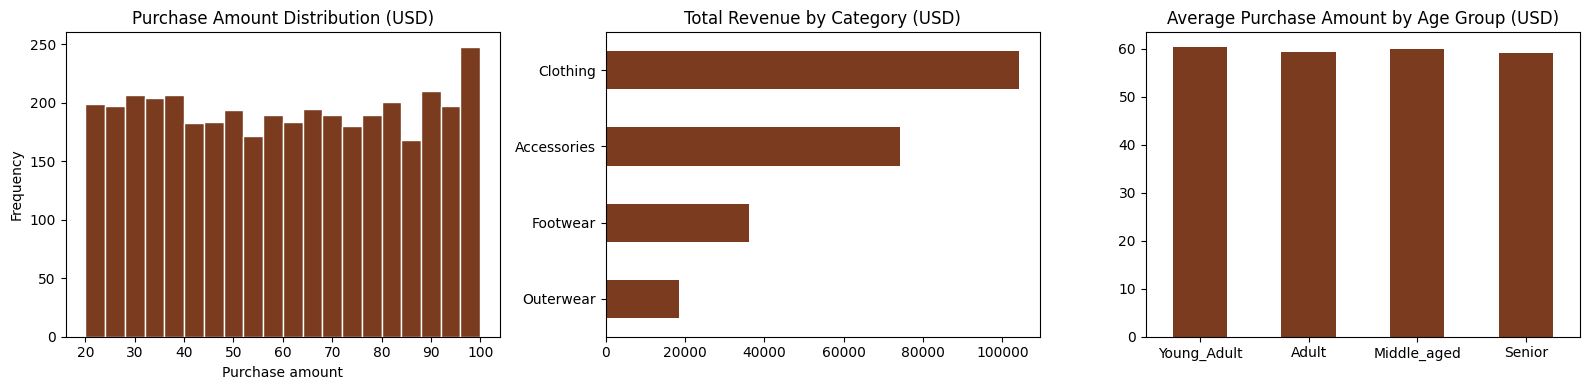

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df['purchase_amount'].plot.hist(bins=20, ax=axes[0], color='#7a3b1e', edgecolor='white')
axes[0].set_title('Purchase Amount Distribution (USD)')
axes[0].set_xlabel('Purchase amount')

df.groupby('category')['purchase_amount'].sum().sort_values().plot.barh(ax=axes[1], color='#7a3b1e')
axes[1].set_title('Total Revenue by Category (USD)')
axes[1].set_ylabel('')

df.groupby('age_group')['purchase_amount'].mean().reindex(labels).plot.bar(ax=axes[2], color='#7a3b1e', rot=0)
axes[2].set_title('Average Purchase Amount by Age Group (USD)')
axes[2].set_xlabel('')

plt.tight_layout()
plt.show()

In [17]:
# Revenue share vs. spend per purchase by gender
df.groupby('gender')['purchase_amount'].agg(customers='count', total_revenue='sum', avg_purchase='mean').round(2)

,customers,total_revenue,avg_purchase
gender,,,
Female,1248,75191,60.25
Male,2652,157890,59.54


**Finding:** Male customers generate ~68% of revenue only because there are more of them (2,652 vs. 1,248).
The average purchase amount is almost the same for both genders (~$60).

In [18]:
# Who has discounts and subscriptions?
pd.concat([
    pd.crosstab(df['gender'], df['discount_applied']).add_prefix('discount_'),
    pd.crosstab(df['gender'], df['subscription_status']).add_prefix('subscription_')
], axis=1)

,discount_No,discount_Yes,subscription_No,subscription_Yes
gender,,,,
Female,1248,0,1248,0
Male,975,1677,1599,1053


**Data limitation:** No female customer has a discount or a subscription in this dataset.
Any comparison of discount or subscription users vs. others is therefore also a comparison of men vs. women,
so these results should be interpreted with care. (The dataset is synthetic.)

## 8. Export & Load into SQL Server

In [19]:
# Save the cleaned dataset so it can be reviewed without SQL Server
df.to_csv('customer_shopping_behavior_cleaned.csv', index=False)

Required packages: `pyodbc`, `sqlalchemy` (see `requirements.txt`).
The connection uses Windows Authentication (`Trusted_Connection`), so no password is stored in the code.

### Code for MS SQL Server

In [20]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

server   = '.'                      # local SQL Server instance
database = 'customer_behavior'
driver   = 'ODBC Driver 17 for SQL Server'

conn_str = (
    f'DRIVER={{{driver}}};'
    f'SERVER={server};'
    f'DATABASE={database};'
    'Trusted_Connection=yes;'
    'TrustServerCertificate=yes;'
)
engine = create_engine(f'mssql+pyodbc:///?odbc_connect={quote_plus(conn_str)}', fast_executemany=True)

pd.read_sql('SELECT @@SERVERNAME AS server_name, DB_NAME() AS database_name;', engine)

,server_name,database_name
0,DESKTOP-PL5571L,customer_behavior


In [21]:
# Write the cleaned DataFrame to SQL Server
df.to_sql('customer', engine, if_exists='replace', index=False)

# Read back a sample (SQL Server uses TOP instead of LIMIT)
pd.read_sql('SELECT TOP 5 * FROM customer;', engine)

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle_aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young_Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle_aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young_Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle_aged,365
